# Synthetic admixture and spatial MMD

Compare the Syndri training pseudo-spatial counts with their matched real CosMx cells, before and after synthetic admixture. The analysis uses the train partition only (Lung5 replicates), excludes Tregs, matches cells by spatial cell ID, and computes RBF MMD² separately for each cell type within each slice. It samples up to 500 query cells per cell type and averages post-admixture scores over three random seeds. The RBF bandwidth is estimated from a fixed random sample of baseline pairwise distances, then held constant for before/after comparisons.

In [18]:
from pathlib import Path
import sys

import anndata as ad
import numpy as np
import pandas as pd
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# Path to where you saved the downloaded Arial file
font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
REPO = Path('/home/jwinchel/Syndri')
FIGURE_DIR = REPO / 'figures' / 'outputs'

REPO = Path('/home/jwinchel/Syndri')
TRAINING_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/spillover-benchmark/train_val.h5ad')
SPATIAL_DIR = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final')
FIGURE_DIR = REPO / 'figures' / 'outputs'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = FIGURE_DIR / 'Figure3_SyndriSIM_MMD_by_slice_celltype.csv'
REUSE_SAVED_MMD = True  # Set False to rerun admixture sampling and recompute MMDs.
MAX_QUERY_PER_CELL_TYPE = 500
RANDOM_SEEDS = (0, 1, 2)

sys.path.insert(0, str(REPO / 'scripts' / 'spillover-benchmark'))
from search_admixture_parameters import normalized_log_counts
sys.path.insert(0, str(REPO / 'Heimdall'))
from Heimdall.admixture_sampling import build_neighbor_dict, sample_admixture_from_neighbor_dict

def squared_distance_matrix(x, y):
    x = np.asarray(x, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    d2 = (x * x).sum(axis=1)[:, None] + (y * y).sum(axis=1)[None, :] - 2.0 * (x @ y.T)
    return np.maximum(d2, 0.0)

def sampled_rbf_bandwidth_squared(x, y, seed=87, n_pairs=10000):
    pooled = np.vstack([x, y]).astype(np.float32, copy=False)
    rng = np.random.default_rng(seed)
    distances = []
    for start in range(0, n_pairs, 1000):
        n = min(1000, n_pairs - start)
        i = rng.integers(0, len(pooled), size=n)
        j = rng.integers(0, len(pooled), size=n)
        d2 = np.square(pooled[i] - pooled[j], dtype=np.float32).sum(axis=1)
        distances.append(d2[d2 > 0])
    positive = np.concatenate(distances)
    return float(np.median(positive)) if positive.size else 1.0

def rbf_mmd_squared_fast(x, y, bandwidth_squared):
    denom = 2.0 * bandwidth_squared
    k_xx = np.exp(-squared_distance_matrix(x, x) / denom)
    k_yy = np.exp(-squared_distance_matrix(y, y) / denom)
    k_xy = np.exp(-squared_distance_matrix(x, y) / denom)
    return float(max(0.0, k_xx.mean() + k_yy.mean() - 2.0 * k_xy.mean()))

if not (REUSE_SAVED_MMD and RESULTS_CSV.exists()):
    training = ad.read_h5ad(TRAINING_PATH)
    training = training[training.obs['split'].astype(str) == 'train'].copy()
    training = training[training.obs['cell_type_harmonized'].astype(str) != 'Treg'].copy()
    slice_names = sorted(training.obs['spatial_slice'].astype(str).unique())
    print(f"Training slices: {slice_names}")
else:
    print(f"Will reuse saved MMD results from {RESULTS_CSV}")


Will reuse saved MMD results from /home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_MMD_by_slice_celltype.csv


In [19]:
if REUSE_SAVED_MMD and RESULTS_CSV.exists():
    summary = pd.read_csv(RESULTS_CSV)
    slice_names = sorted(summary['slice'].astype(str).unique())
    print(f"Loaded {len(summary)} saved slice/cell-type MMD rows from {RESULTS_CSV}")
else:
    if REUSE_SAVED_MMD:
        print(f"Saved MMD CSV not found at {RESULTS_CSV}; recomputing results.")
    from scipy.sparse import csr_matrix

    records = []
    for slice_idx, slice_name in enumerate(slice_names):
        mapped = training[training.obs['spatial_slice'].astype(str) == slice_name].copy()
        mapped = mapped[mapped.obs['cell_type_harmonized'].astype(str) != 'Treg'].copy()
        spatial_path = SPATIAL_DIR / f'st_integrated_slice-{slice_name}.h5ad'
        spatial = ad.read_h5ad(spatial_path)
        spatial = spatial[spatial.obs['cell_type_harmonized'].astype(str) != 'Treg'].copy()
        prefix = f"{slice_name}:"
        spatial_ids = [str(cell_id)[len(prefix):] for cell_id in mapped.obs_names]
        spatial_rows = spatial.obs_names.astype(str).get_indexer(spatial_ids)
        if (spatial_rows < 0).any():
            raise ValueError(f"Could not pair mapped and spatial cells for {slice_name}")
        spatial = spatial[spatial_rows].copy()
        cell_types = mapped.obs['cell_type_harmonized'].astype(str).to_numpy()
        if not np.array_equal(cell_types, spatial.obs['cell_type_harmonized'].astype(str).to_numpy()):
            raise ValueError(f"Cell type annotations disagree for {slice_name}")
        shared = mapped.var_names.intersection(spatial.var_names)
        mapped = mapped[:, shared].copy()
        spatial = spatial[:, shared].copy()

        rng = np.random.default_rng(91827)
        query_ids = []
        for cell_type in sorted(np.unique(cell_types)):
            ids = mapped.obs_names[cell_types == cell_type].astype(str).to_numpy()
            if len(ids) < 2:
                continue
            query_ids.extend(rng.choice(ids, size=min(len(ids), MAX_QUERY_PER_CELL_TYPE), replace=False).tolist())
        query_rows = mapped.obs_names.astype(str).get_indexer(query_ids)
        spatial_query = spatial[query_rows].copy()
        query_labels = mapped.obs.iloc[query_rows]["cell_type_harmonized"].astype(str).to_numpy()
        base_expression = normalized_log_counts(mapped.X[query_rows])
        real_expression = normalized_log_counts(spatial_query.X)
        stratum_data = {}
        for cell_type in sorted(np.unique(query_labels)):
            mask = query_labels == cell_type
            x0, y = base_expression[mask], real_expression[mask]
            bandwidth = sampled_rbf_bandwidth_squared(x0, y, seed=91827 + slice_idx)
            stratum_data[cell_type] = (mask, x0, y, bandwidth)

        mapped.obs['cell_type'] = mapped.obs['cell_type_harmonized'].astype(str)
        mapped = build_neighbor_dict(
            mapped, k_neighbors=9, coord_cols=("CenterX_global_px", "CenterY_global_px"),
            tissue_col="spatial_slice", cell_type_col="cell_type",
            min_source_counts=400, use_same_cell_type_neighbors=False,
        )
        full_neighbors = mapped.uns['neighbor_dict']
        query_neighbors = {cell_id: full_neighbors.get(cell_id, []) for cell_id in query_ids}
        neighbor_ids = list(dict.fromkeys(nid for ids in query_neighbors.values() for nid in ids))
        selected_ids = list(dict.fromkeys(query_ids + neighbor_ids))
        sampling_data = mapped[selected_ids].copy()
        sampling_data.uns['neighbor_dict'] = query_neighbors
        sample_query_rows = sampling_data.obs_names.astype(str).get_indexer(query_ids)

        for seed in RANDOM_SEEDS:
            added, _ = sample_admixture_from_neighbor_dict(
                sampling_data, tau_range=(0.0, 0.95), n_repeats=1,
                min_sampled_transcript_threshold=10, only_sample_unexpressed_genes=True,
                rng=np.random.default_rng(seed + 1000 * slice_idx), return_sparse=True,
            )
            admixed = normalized_log_counts(sampling_data.X[sample_query_rows] + added[sample_query_rows])
            for cell_type, (mask, x0, y, bandwidth) in stratum_data.items():
                records.append({
                    "slice": slice_name, "cell_type": cell_type, "seed": seed,
                    "mmd2_before": rbf_mmd_squared_fast(x0, y, bandwidth),
                    "mmd2_after": rbf_mmd_squared_fast(admixed[mask], y, bandwidth),
                    "n_query": int(mask.sum()),
                })
        print(f"Finished {slice_name}: {len(stratum_data)} cell-type strata", flush=True)

    results = pd.DataFrame(records)
    summary = (results.groupby(["slice", "cell_type"], as_index=False)
               .agg(mmd2_before=("mmd2_before", "first"),
                    mmd2_after_mean=("mmd2_after", "mean"),
                    mmd2_after_sd=("mmd2_after", "std"),
                    n_query=("n_query", "first")))
    summary["mmd2_after_sd"] = summary["mmd2_after_sd"].fillna(0.0)
    summary["delta_mmd2"] = summary["mmd2_after_mean"] - summary["mmd2_before"]
    summary.to_csv(FIGURE_DIR / "Figure3_SyndriSIM_MMD_by_slice_celltype.csv", index=False)
    summary.head()


Loaded 42 saved slice/cell-type MMD rows from /home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_MMD_by_slice_celltype.csv


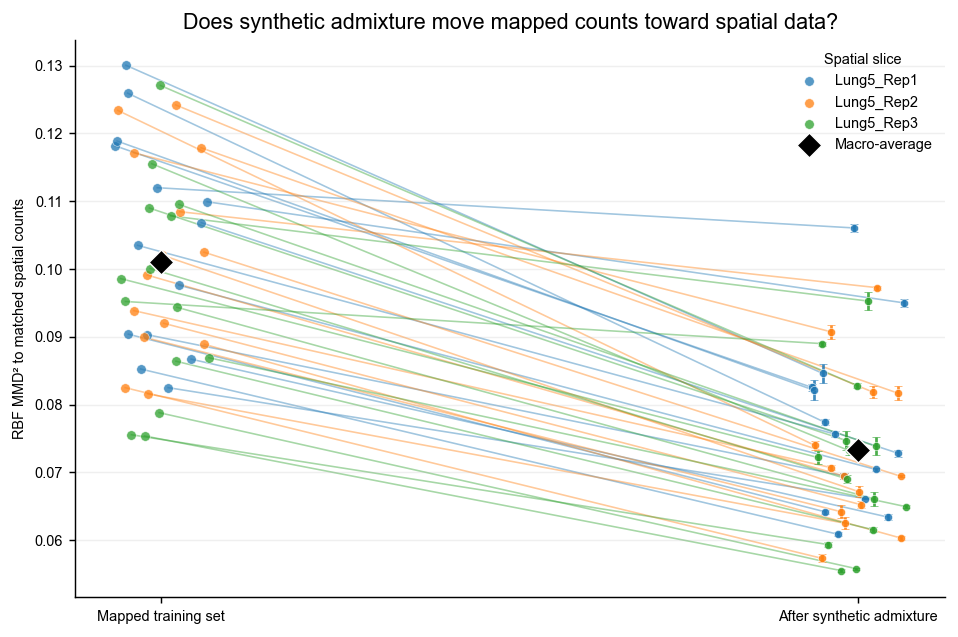

Equal-weight mean across slice/cell-type strata: 0.1010 before, 0.0732 after
Relative change: -27.5%


In [20]:
# Paired stratum-level values; lower MMD² means closer to the real spatial counts.
fig, ax = plt.subplots(figsize=(7.5, 5.0))
x_before, x_after = 0, 1
slice_colors = dict(zip(slice_names, plt.get_cmap("tab10").colors))
rng = np.random.default_rng(1729)
for slice_name, group in summary.groupby("slice", sort=True):
    jitter = rng.uniform(-0.07, 0.07, size=len(group))
    color = slice_colors[slice_name]
    for j, (_, row) in enumerate(group.iterrows()):
        ax.plot([x_before + jitter[j], x_after + jitter[j]],
                [row.mmd2_before, row.mmd2_after_mean],
                color=color, alpha=0.42, linewidth=0.9, zorder=1)
    ax.scatter(x_before + jitter, group.mmd2_before, color=color, s=28,
               alpha=0.75, edgecolor="white", linewidth=0.35, label=slice_name, zorder=2)
    ax.errorbar(x_after + jitter, group.mmd2_after_mean,
                yerr=group.mmd2_after_sd, fmt="o", color=color,
                markersize=4.5, capsize=2, alpha=0.85,
                markeredgecolor="white", markeredgewidth=0.35, zorder=3)

overall_before = summary.mmd2_before.mean()
overall_after = summary.mmd2_after_mean.mean()
ax.scatter([x_before, x_after], [overall_before, overall_after],
           marker="D", s=95, color="black", edgecolor="white",
           linewidth=0.8, label="Macro-average", zorder=5)
ax.set_xticks([x_before, x_after], ["Mapped training set", "After synthetic admixture"])
ax.set_ylabel("RBF MMD² to matched spatial counts", fontsize=8)
ax.set_title("Does synthetic admixture move mapped counts toward spatial data?", fontsize=12)
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="both", labelsize=8)
ax.legend(title="Spatial slice", frameon=False, fontsize=8, title_fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "Figure3_SyndriSIM_MMD.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "Figure3_SyndriSIM_MMD.pdf", bbox_inches="tight")
plt.show()
print(f"Equal-weight mean across slice/cell-type strata: {overall_before:.4f} before, {overall_after:.4f} after")
print(f"Relative change: {(overall_after / overall_before - 1) * 100:.1f}%")

## MMD by admixture phase and replicate

Each box summarizes the cell-type-level MMD² values for one replicate. The before/after values are paired by slice and cell type in the source table.

['1', '2', '3']
         slice   phase      mmd2 replicate
0   Lung5_Rep1  Before  0.118192         1
1   Lung5_Rep1  Before  0.090390         1
2   Lung5_Rep1  Before  0.085259         1
3   Lung5_Rep1  Before  0.082506         1
4   Lung5_Rep1  Before  0.086705         1
..         ...     ...       ...       ...
79  Lung5_Rep3   After  0.064950         3
80  Lung5_Rep3   After  0.073846         3
81  Lung5_Rep3   After  0.073235         3
82  Lung5_Rep3   After  0.072212         3
83  Lung5_Rep3   After  0.066096         3

[84 rows x 4 columns]


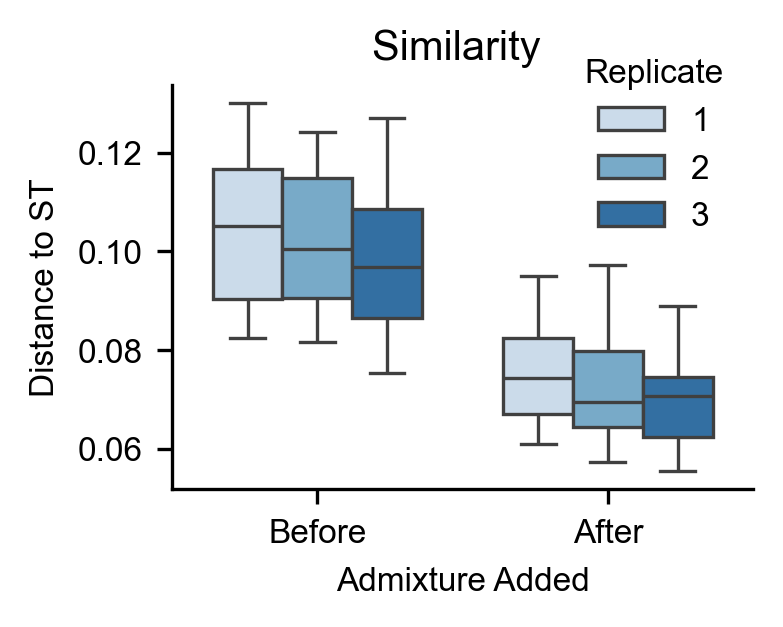

In [57]:
import seaborn as sns
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
# sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,

})

# Boxplot of MMD by admixture phase and spatial replicate.
boxplot_summary = summary if "summary" in globals() else pd.read_csv(RESULTS_CSV)
boxplot_long = boxplot_summary.melt(
    id_vars=["slice"],
    value_vars=["mmd2_before", "mmd2_after_mean"],
    var_name="phase", value_name="mmd2",
)
phase_labels = {"mmd2_before": "Before",
                "mmd2_after_mean": "After"}
boxplot_long["phase"] = boxplot_long["phase"].map(phase_labels)
boxplot_long["replicate"] = boxplot_long["slice"].apply(lambda x: str(x[-1:]))
replicate_order = ['1','2','3']
print(replicate_order)
# replicate_palette = dict(zip(replicate_order, plt.get_cmap("deep").colors))
print(boxplot_long)
fig, ax = plt.subplots(figsize=(2.5, 1.75), dpi=300)
sns.boxplot(
    data=boxplot_long, x="phase", y="mmd2", hue="replicate",
    order=["Before", "After"],
    hue_order=replicate_order, palette='Blues',
    showfliers=False, width=0.72, linewidth=0.8, ax=ax,
)
ax.set(xlabel="", ylabel="Distance to ST",
       )
ax.set_title("Similarity ", fontsize=10)
ax.tick_params(axis="both", labelsize=8)
ax.set_xlabel("Admixture Added", fontsize=8)
ax.set_ylabel(ax.get_ylabel(), fontsize=8)
ax.grid(False, axis="x")
ax.grid(False, axis="y")
ax.legend(title="Replicate", frameon=False, loc="center right", fontsize=8, title_fontsize=8,bbox_to_anchor=(1.0,0.85))
# fig.tight_layout()
fig.savefig(FIGURE_DIR / "Figure3_SyndriSIM_MMD_boxplot.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "Figure3_distToST.svg")
plt.show()


## Known synthetic-admixture removal on the test set

For each test slice, average precision evaluates whether counts known to be synthetically added are ranked for removal. A second measure reports the fraction of known added counts removed, capping attributed removal at the amount actually added. A third reports the fraction of original counts removed at entries without synthetic additions. SPLIT results are read from the merged corrected layers in the test directory. Set `SYNDRI_REMOVAL_THRESHOLD` in the code cell to change Syndri's hard-zero threshold; each threshold has a separate cached metrics file. Set `RESULTS_TO_RECOMPUTE = {'test_removal_metrics'}` to recompute removal metrics, `{'roc_pr_curves'}` to recompute the curves, or add `'coexpression_matrix'` to rebuild the three coexpression panels; an empty set reuses all caches.

The ROC plot uses Syndri's `admix_probs`. The PR plot compares ResolVI, Syndri, Syndri (binarized), and SPLIT. The original Syndri curve uses `admix_probs`; Syndri (binarized) first chooses the pooled probability cutoff with the best F1, hard-zeros counts at that cutoff, then uses `1 - corrected/admixed` like ResolVI and SPLIT. Raw is omitted, with positive prevalence shown as the random-ranking reference; entries with synthetic admixture are positives. Curves pool observed cell–gene entries across test slices; up to 2,000 points per curve are cached for plotting, while AUROC, average precision (AP), and trapezoidal AUPRC use all entries. The PR summary reports both AP and AUPRC for each method and its binarized version. Include `'roc_pr_curves'` in `RESULTS_TO_RECOMPUTE` to rebuild them from prediction files.
The final cell shows cross-cell-type marker-gene co-detection matrices for the full scRNA-seq reference, all mapped Lung5_Rep1 train/validation cells, and the real Lung5_Rep1 ST slice. It uses the top three available DESeq2 markers per cell type and displays cell-type labels centered across each three-gene block on both axes, ordered by the Figure 2 cell-type families; the gene-symbol aliases remain available in the marker table above the plots. Every matrix entry is the fraction of all cells in that dataset (or Lung5_Rep1 simulated slice) detecting both genes, regardless of their cell-type labels. Add `'coexpression_matrix'` to `RESULTS_TO_RECOMPUTE` to rebuild its cache.


Loaded cached test-set removal metrics from /home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_test_removal_metrics_syndri_threshold_0p500.csv


,slice,method,auprc,known_removed_fraction,unadmixed_removed_fraction,n_cells,status
0,Lung12,Raw,0.406301,0.000000,0.000000,71286,ok
1,Lung12,ResolVI,0.560068,0.310061,0.251206,71286,ok
2,Lung12,Syndri,0.694638,0.988886,0.440220,71286,ok
3,Lung12,SPLIT,0.582664,0.537816,0.344970,71286,ok
4,Lung13,Raw,0.363590,0.000000,0.000000,78992,ok
5,Lung13,ResolVI,0.526746,0.356356,0.277786,78992,ok
6,Lung13,Syndri,0.660137,0.987442,0.335584,78992,ok
7,Lung13,SPLIT,0.505754,0.498309,0.318943,78992,ok
8,Lung9_Rep1,Raw,0.354620,0.000000,0.000000,86337,ok
9,Lung9_Rep1,ResolVI,0.534648,0.308882,0.281550,86337,ok


,method,auprc,average_precision,best_f1,best_f1_threshold
0,ResolVI,0.532482,0.532381,0.570669,0.047124
1,ResolVI (binarized),0.660372,0.425106,0.570668,0.047124
2,Syndri,0.888390,0.888386,0.804466,0.762290
3,Syndri (binarized),0.835575,0.708173,0.804466,0.762290
4,SPLIT,0.537075,0.533510,0.580403,0.142894
5,SPLIT (binarized),0.664528,0.436269,0.580403,0.142894


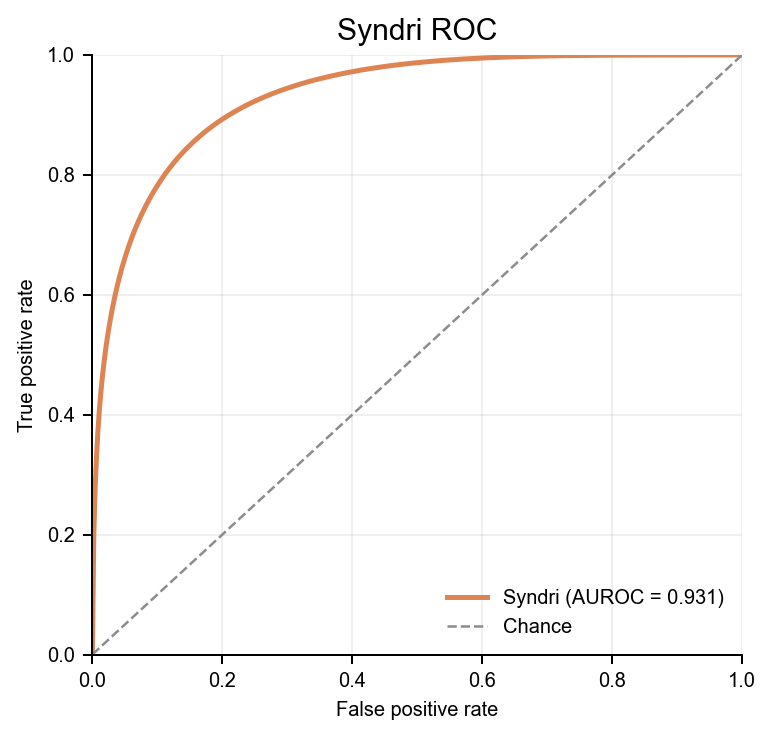

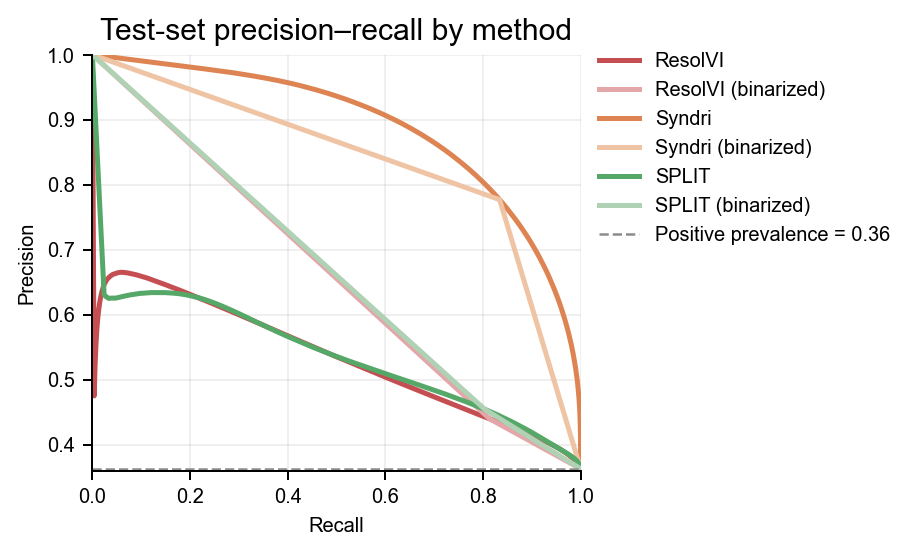

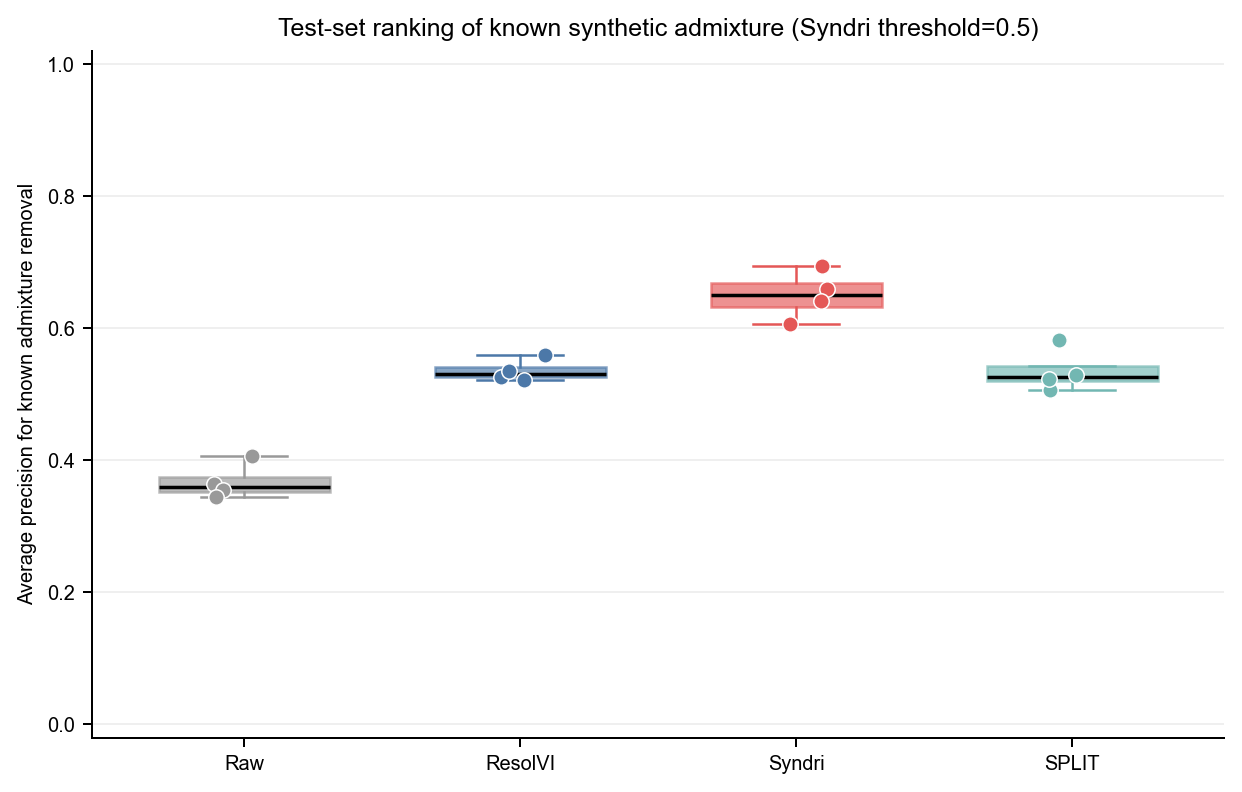

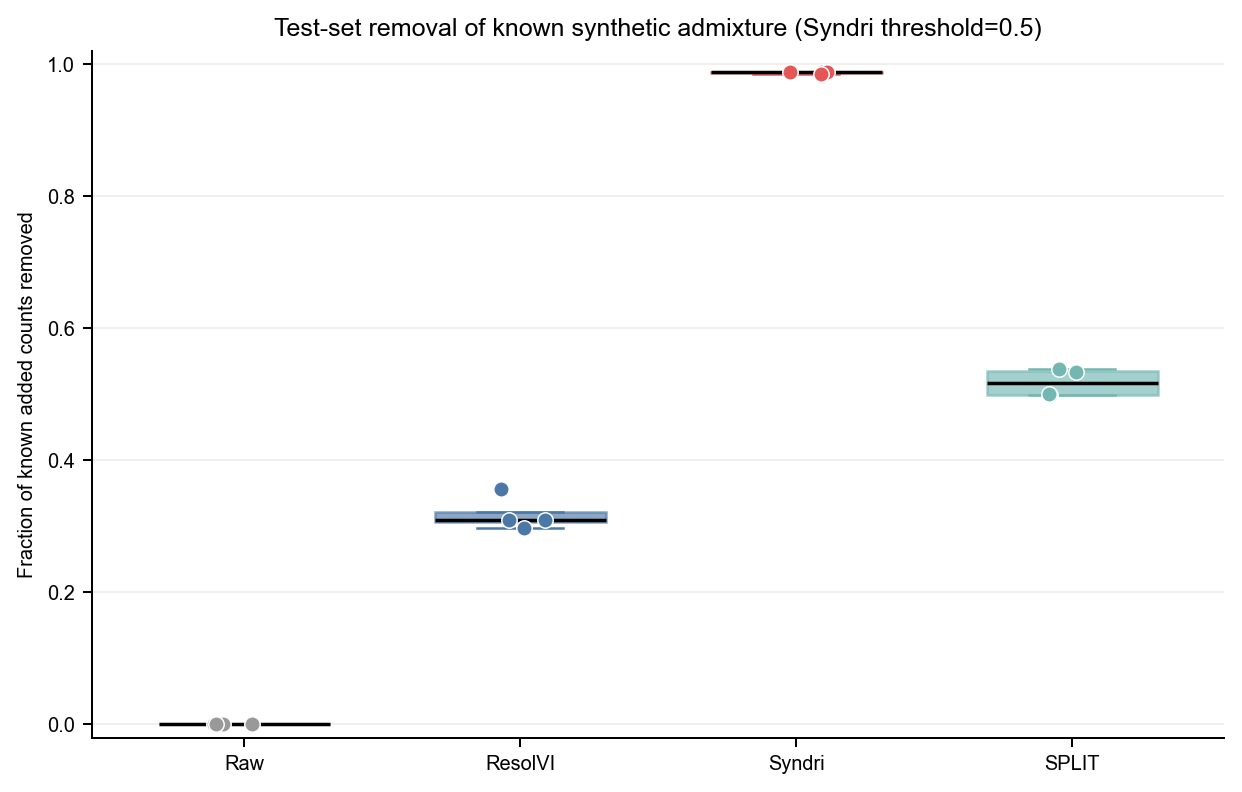

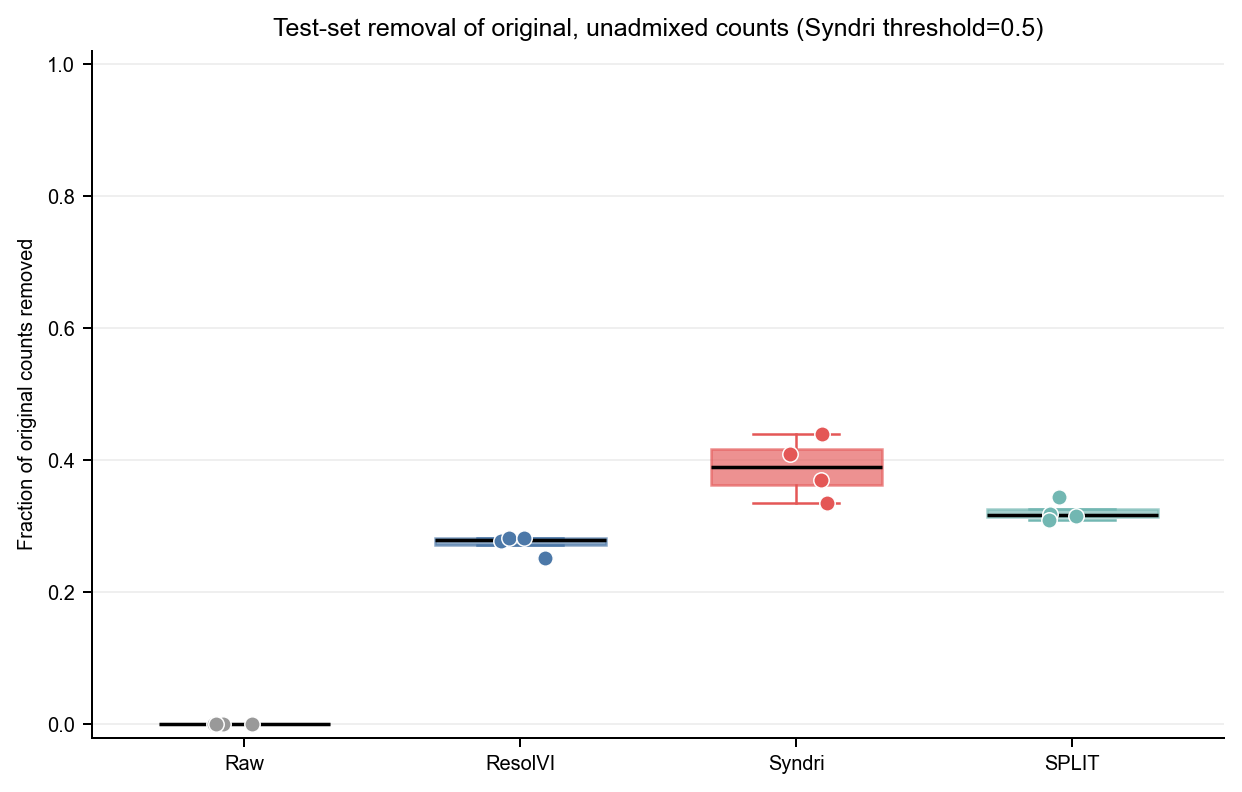

In [ ]:
from scipy import sparse
from sklearn.metrics import (
    average_precision_score, auc, precision_recall_curve, roc_curve,
)

TEST_ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/spillover-benchmark/test_admixture')
TEST_SLICES_DIR = TEST_ROOT / 'slices'
RESOLVI_DIR = TEST_ROOT / 'resolvi'
SYNDRI_DIR = TEST_ROOT / 'syndri'
SPLIT_MERGED_DIR = TEST_ROOT / 'split' / 'merged_h5ad'
# Choose cached result groups to recompute on this run. Use either or both:
#   'test_removal_metrics'  per-slice removal summary table
#   'roc_pr_curves'         pooled ROC/PR curves
#   'binarized_method_curves' ResolVI/SPLIT best-F1 hard-zero curves
#   'cell_type_adjacency' KNN adjacency enrichment for simulated/real Lung5_Rep1
RESULTS_TO_RECOMPUTE = set()
VALID_RESULT_GROUPS = {'test_removal_metrics', 'roc_pr_curves',
                       'binarized_method_curves', 'coexpression_matrix', 'cell_type_adjacency'}
unknown_result_groups = RESULTS_TO_RECOMPUTE - VALID_RESULT_GROUPS
if unknown_result_groups:
    raise ValueError(f'Unknown result groups: {sorted(unknown_result_groups)}')

SYNDRI_REMOVAL_THRESHOLD = 0.5  # Hard-zero a count when admix_probs >= this value.
if not 0.0 <= SYNDRI_REMOVAL_THRESHOLD <= 1.0:
    raise ValueError('SYNDRI_REMOVAL_THRESHOLD must be between 0 and 1.')
threshold_tag = f'{SYNDRI_REMOVAL_THRESHOLD:.3f}'.replace('.', 'p')
REMOVAL_RESULTS_CSV = FIGURE_DIR / f'Figure3_SyndriSIM_test_removal_metrics_syndri_threshold_{threshold_tag}.csv'
REUSE_CACHED_REMOVAL_RESULTS = 'test_removal_metrics' not in RESULTS_TO_RECOMPUTE


def dense_matrix(matrix):
    return matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)


def slice_removal_metrics(admixed, corrected, labels, original):
    """Return AP and fraction of known added counts removed for one slice."""
    admixed = dense_matrix(admixed).astype(np.float64, copy=False)
    corrected = dense_matrix(corrected).astype(np.float64, copy=False)
    labels = dense_matrix(labels).astype(np.float64, copy=False)
    original = dense_matrix(original).astype(np.float64, copy=False)
    if (admixed.shape != corrected.shape or admixed.shape != labels.shape
            or admixed.shape != original.shape):
        raise ValueError('Admixed counts, corrected counts, and labels must have the same shape.')

    # AP ranks observed cell-gene entries by their proportional count reduction.
    mask = admixed > 0
    y_true = (labels[mask] > 0).astype(np.uint8)
    if y_true.sum() == 0:
        auprc = np.nan
    else:
        removal_score = 1.0 - corrected[mask] / admixed[mask]
        finite = np.isfinite(removal_score)
        auprc = (float(average_precision_score(y_true[finite], removal_score[finite]))
                 if finite.any() and y_true[finite].sum() > 0 else np.nan)

    # Credit only the known added amount; removing more than that cannot inflate this fraction.
    known_total = labels.sum()
    if known_total <= 0:
        known_removed_fraction = np.nan
    else:
        removed = np.minimum(labels, np.maximum(admixed - corrected, 0.0))
        known_removed_fraction = float(removed.sum() / known_total)
    # Measure count-weighted loss of original counts only where no synthetic counts were added.
    unadmixed_original = np.where(labels <= 0, original, 0.0)
    unadmixed_total = unadmixed_original.sum()
    if unadmixed_total <= 0:
        unadmixed_removed_fraction = np.nan
    else:
        removed_unadmixed = np.minimum(
            unadmixed_original, np.maximum(admixed - corrected, 0.0)
        )
        unadmixed_removed_fraction = float(removed_unadmixed.sum() / unadmixed_total)
    return auprc, known_removed_fraction, unadmixed_removed_fraction


def score_corrected_adata(source, corrected_adata, corrected_layer, method):
    """Align output by cell/gene IDs and score it against the source truth."""
    cell_idx = source.obs_names.get_indexer(corrected_adata.obs_names)
    gene_idx = source.var_names.get_indexer(corrected_adata.var_names)
    if (cell_idx < 0).any():
        raise ValueError('Correction output contains cells absent from the source test slice.')
    if (gene_idx < 0).any():
        raise ValueError('Correction output contains genes absent from the source test slice.')
    aligned_source = source[cell_idx, gene_idx]

    if method == 'Syndri':
        if 'admix_probs' not in corrected_adata.layers:
            raise KeyError("Syndri output is missing the 'admix_probs' layer.")
        probabilities = dense_matrix(corrected_adata.layers['admix_probs'])
        admixed = dense_matrix(aligned_source.layers['admixed_counts'])
        if probabilities.shape != admixed.shape:
            raise ValueError('Syndri admix_probs and aligned source counts have different shapes.')
        # Match clean_syndri_predictions.py: set counts to zero at/above the threshold.
        corrected_counts = np.where(
            probabilities >= SYNDRI_REMOVAL_THRESHOLD, 0.0, admixed
        )
    else:
        if corrected_layer not in corrected_adata.layers:
            raise KeyError(f'Missing correction layer {corrected_layer!r}.')
        corrected_counts = corrected_adata.layers[corrected_layer]

    auprc, fraction_removed, unadmixed_removed_fraction = slice_removal_metrics(
        aligned_source.layers['admixed_counts'],
        corrected_counts,
        aligned_source.layers['synthetic_admixture_counts'],
        aligned_source.layers['original_counts'],
    )
    return auprc, fraction_removed, unadmixed_removed_fraction, int(len(cell_idx))

method_order = ['Raw', 'ResolVI', 'Syndri', 'SPLIT']
cached_removal_results = (
    pd.read_csv(REMOVAL_RESULTS_CSV)
    if REUSE_CACHED_REMOVAL_RESULTS and REMOVAL_RESULTS_CSV.is_file()
    else None
)
required_cache_columns = {
    'slice', 'method', 'auprc', 'known_removed_fraction',
    'unadmixed_removed_fraction', 'n_cells', 'status',
}
if cached_removal_results is not None and required_cache_columns.issubset(cached_removal_results.columns):
    removal_results = cached_removal_results
    print(f'Loaded cached test-set removal metrics from {REMOVAL_RESULTS_CSV}')
else:
    if cached_removal_results is not None:
        print('Cached results have an old schema; recomputing test-set removal metrics.')
    removal_rows = []
    for slice_path in sorted(TEST_SLICES_DIR.glob('Lung*.h5ad')):
        slice_name = slice_path.stem
        source = ad.read_h5ad(slice_path)
        required_truth_layers = {'admixed_counts', 'synthetic_admixture_counts', 'original_counts'}
        missing_truth = required_truth_layers - set(source.layers.keys())
        if missing_truth:
            raise KeyError(f'{slice_path} is missing test-truth layers: {sorted(missing_truth)}')

        raw_auprc, raw_fraction_removed, raw_unadmixed_removed = slice_removal_metrics(
            source.layers['admixed_counts'],
            source.layers['admixed_counts'],
            source.layers['synthetic_admixture_counts'],
            source.layers['original_counts'],
        )
        removal_rows.append(dict(slice=slice_name, method='Raw', auprc=raw_auprc,
                                 known_removed_fraction=raw_fraction_removed,
                                 unadmixed_removed_fraction=raw_unadmixed_removed,
                                 n_cells=source.n_obs, status='ok'))

        method_outputs = {
            'ResolVI': (RESOLVI_DIR / f'{slice_name}.h5ad', 'resolvi_corrected_counts'),
            'Syndri': (SYNDRI_DIR / f'{slice_name}_syndri_predictions.h5ad', 'admix_probs'),
            'SPLIT': (SPLIT_MERGED_DIR / f'{slice_name}.h5ad', 'split_purified_counts_X'),
        }
        for method, (output_path, layer) in method_outputs.items():
            if not output_path.is_file():
                status = 'pending' if method == 'SPLIT' else 'missing'
                removal_rows.append(dict(slice=slice_name, method=method, auprc=np.nan,
                                         known_removed_fraction=np.nan,
                                         unadmixed_removed_fraction=np.nan, n_cells=0, status=status))
                continue
            output = ad.read_h5ad(output_path)
            if method != 'Syndri' and layer not in output.layers:
                status = 'pending' if method == 'SPLIT' else 'missing_layer'
                removal_rows.append(dict(slice=slice_name, method=method, auprc=np.nan,
                                         known_removed_fraction=np.nan,
                                         unadmixed_removed_fraction=np.nan, n_cells=0, status=status))
                continue
            auprc, fraction_removed, unadmixed_removed, n_cells = score_corrected_adata(
                source, output, layer, method
            )
            removal_rows.append(dict(slice=slice_name, method=method, auprc=auprc,
                                     known_removed_fraction=fraction_removed,
                                     unadmixed_removed_fraction=unadmixed_removed,
                                     n_cells=n_cells, status='ok'))

    removal_results = pd.DataFrame(removal_rows)
    removal_results.to_csv(REMOVAL_RESULTS_CSV, index=False)
    display(removal_results)
display(removal_results)

# Pool observed cell-gene entries across test slices for method-wise PR curves.
# Versioned cache records the additional probability-thresholded Syndri curve.
CURVE_RESULTS_CSV = FIGURE_DIR / 'Figure3_SyndriSIM_test_method_roc_pr_curves_with_syndri_binarized.csv'
REUSE_CACHED_CURVE_RESULTS = 'roc_pr_curves' not in RESULTS_TO_RECOMPUTE
curve_cache_columns = {
    'curve', 'method', 'x', 'y', 'threshold', 'metric_name',
    'metric_value', 'positive_prevalence', 'best_f1', 'best_f1_threshold',
    'auprc', 'average_precision',
}
pr_method_order = ['ResolVI', 'ResolVI (binarized)', 'Syndri',
                   'Syndri (binarized)', 'SPLIT', 'SPLIT (binarized)']
MAX_CURVE_POINTS = 2000  # Thin plotted curves; AUROC/AP are still computed at full resolution.

def curve_point_indices(n_points):
    return np.unique(np.linspace(
        0, n_points - 1, min(n_points, MAX_CURVE_POINTS), dtype=int
    ))

if REUSE_CACHED_CURVE_RESULTS and CURVE_RESULTS_CSV.is_file():
    method_curve_data = pd.read_csv(CURVE_RESULTS_CSV)
    if not curve_cache_columns.issubset(method_curve_data.columns):
        method_curve_data = None
else:
    method_curve_data = None

if method_curve_data is None:
    curve_method_layers = {
        'ResolVI': (RESOLVI_DIR, '', 'resolvi_corrected_counts'),
        'Syndri': (SYNDRI_DIR, '_syndri_predictions', 'admix_probs'),
        'SPLIT': (SPLIT_MERGED_DIR, '', 'split_purified_counts_X'),
    }
    pooled_labels_by_method = {method: [] for method in pr_method_order}
    pooled_scores_by_method = {method: [] for method in pr_method_order}
    pooled_admixed_for_syndri = []
    for slice_path in sorted(TEST_SLICES_DIR.glob('Lung*.h5ad')):
        slice_name = slice_path.stem
        source = ad.read_h5ad(slice_path)
        required_truth_layers = {'admixed_counts', 'synthetic_admixture_counts'}
        missing = required_truth_layers - set(source.layers.keys())
        if missing:
            raise KeyError(f'{slice_path} is missing layers needed for PR curves: {sorted(missing)}')
        admixed = dense_matrix(source.layers['admixed_counts'])
        labels = dense_matrix(source.layers['synthetic_admixture_counts'])
        observed = admixed > 0


        for method, (output_dir, suffix, layer) in curve_method_layers.items():
            output_path = output_dir / f'{slice_name}{suffix}.h5ad'
            if not output_path.is_file():
                continue
            output = ad.read_h5ad(output_path)
            if layer not in output.layers:
                continue
            cell_idx = source.obs_names.get_indexer(output.obs_names)
            gene_idx = source.var_names.get_indexer(output.var_names)
            if (cell_idx < 0).any() or (gene_idx < 0).any():
                raise ValueError(f'{output_path} has cell or gene IDs absent from its source slice.')
            aligned_source = source[cell_idx, gene_idx]
            aligned_admixed = dense_matrix(aligned_source.layers['admixed_counts'])
            aligned_labels = dense_matrix(aligned_source.layers['synthetic_admixture_counts'])
            if method == 'Syndri':
                scores = dense_matrix(output.layers[layer])
            else:
                corrected = dense_matrix(output.layers[layer])
                if corrected.shape != aligned_admixed.shape:
                    raise ValueError(f'{slice_name}: {method} correction and source have different shapes.')
                # These are ranking scores; values may fall outside [0, 1] if a
                # correction increases counts, which sklearn PR curves support.
                ratio = np.zeros(
                    corrected.shape,
                    dtype=np.result_type(corrected.dtype, aligned_admixed.dtype, np.float32),
                )
                np.divide(
                    corrected, aligned_admixed, out=ratio, where=aligned_admixed > 0
                )
                scores = 1.0 - ratio
            if scores.shape != aligned_admixed.shape or aligned_labels.shape != aligned_admixed.shape:
                raise ValueError(f'{slice_name}: {method} scores and source layers have different shapes.')
            finite = (aligned_admixed > 0) & np.isfinite(scores)
            pooled_labels_by_method[method].append((aligned_labels[finite] > 0).astype(np.uint8))
            pooled_scores_by_method[method].append(scores[finite].astype(np.float32, copy=False))
            if method == 'Syndri':
                pooled_admixed_for_syndri.append(aligned_admixed[finite].astype(np.float32, copy=False))

    # Use the pooled best-F1 cutoff from Syndri's probability curve to create
    # a hard-zeroed count correction, then score it like ResolVI and SPLIT.
    syndri_label_parts = pooled_labels_by_method['Syndri']
    syndri_score_parts = pooled_scores_by_method['Syndri']
    if syndri_label_parts and sum(len(x) for x in syndri_label_parts):
        syndri_labels = np.concatenate(syndri_label_parts)
        syndri_probabilities = np.concatenate(syndri_score_parts)
        syndri_admixed_counts = np.concatenate(pooled_admixed_for_syndri)
        probability_precision, probability_recall, probability_thresholds = (
            precision_recall_curve(syndri_labels, syndri_probabilities)
        )
        probability_f1_denominator = probability_precision[1:] + probability_recall[1:]
        probability_f1 = np.divide(
            2 * probability_precision[1:] * probability_recall[1:],
            probability_f1_denominator,
            out=np.zeros_like(probability_f1_denominator, dtype=float),
            where=probability_f1_denominator > 0,
        )
        if len(probability_f1):
            best_probability_idx = int(np.argmax(probability_f1))
            best_probability_threshold = float(probability_thresholds[best_probability_idx])
            binarized_corrected_counts = np.where(
                syndri_probabilities >= best_probability_threshold,
                0.0, syndri_admixed_counts,
            )
            binarized_removal_scores = 1.0 - (
                binarized_corrected_counts / syndri_admixed_counts
            )
            pooled_labels_by_method['Syndri (binarized)'].append(syndri_labels)
            pooled_scores_by_method['Syndri (binarized)'].append(binarized_removal_scores)
            print(
                'Syndri (binarized) uses pooled best-F1 admix_probs cutoff '
                f'{best_probability_threshold:.6g}'
            )

    curve_rows = []
    for method in pr_method_order:
        label_parts = pooled_labels_by_method[method]
        score_parts = pooled_scores_by_method[method]
        if not label_parts or sum(len(x) for x in label_parts) == 0:
            continue
        y_true = np.concatenate(label_parts)
        y_score = np.concatenate(score_parts)
        if y_true.sum() == 0:
            continue
        positive_prevalence = float(y_true.mean())
        if method == 'Syndri' and np.unique(y_true).size == 2:
            fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
            roc_auc = float(auc(fpr, tpr))
            roc_indices = curve_point_indices(len(fpr))
            curve_rows.extend(
                dict(curve='ROC', method=method, x=fpr[i], y=tpr[i],
                     threshold=roc_thresholds[i], metric_name='AUROC',
                     metric_value=roc_auc, positive_prevalence=positive_prevalence)
                for i in roc_indices
            )
        precision, recall, pr_thresholds = precision_recall_curve(y_true, y_score)
        pr_ap = float(average_precision_score(y_true, y_score))
        pr_auprc = float(auc(recall, precision))
        # sklearn thresholds align with precision[1:] and recall[1:].
        threshold_precision = precision[1:]
        threshold_recall = recall[1:]
        f1_denominator = threshold_precision + threshold_recall
        f1_values = np.divide(
            2 * threshold_precision * threshold_recall,
            f1_denominator,
            out=np.zeros_like(f1_denominator, dtype=float),
            where=f1_denominator > 0,
        )
        if len(f1_values):
            best_f1_idx = int(np.argmax(f1_values))
            best_f1 = float(f1_values[best_f1_idx])
            best_f1_threshold = float(pr_thresholds[best_f1_idx])
            if method == 'Syndri (binarized)':
                # Report F1 for the fixed probability cutoff used to create the
                # binarized counts, rather than optimizing a second threshold.
                best_f1 = float(probability_f1[best_probability_idx])
                best_f1_threshold = best_probability_threshold
        else:
            best_f1 = np.nan
            best_f1_threshold = np.nan
        padded_thresholds = np.append(pr_thresholds, np.nan)
        pr_indices = curve_point_indices(len(recall))
        curve_rows.extend(
            dict(curve='PR', method=method, x=recall[i], y=precision[i],
                 threshold=padded_thresholds[i], metric_name='AUPRC',
                 metric_value=pr_auprc, auprc=pr_auprc, average_precision=pr_ap,
                 positive_prevalence=positive_prevalence, best_f1=best_f1,
                 best_f1_threshold=best_f1_threshold)
            for i in pr_indices
        )
    method_curve_data = pd.DataFrame(curve_rows, columns=sorted(curve_cache_columns))
    method_curve_data.to_csv(CURVE_RESULTS_CSV, index=False)
    print(f'Saved pooled method ROC/PR curve data to {CURVE_RESULTS_CSV}')


# Binarize ResolVI and SPLIT using each method's pooled continuous-score
# best-F1 cutoff. Counts are either zeroed or kept unchanged, then scored as
# 1 - corrected_binarized / admixed. Reuse base curves and add only these
# two additional PR curves.
binary_method_specs = {
    'ResolVI (binarized)': ('ResolVI', RESOLVI_DIR, '', 'resolvi_corrected_counts'),
    'SPLIT (binarized)': ('SPLIT', SPLIT_MERGED_DIR, '', 'split_purified_counts_X'),
}
existing_pr_methods = set(method_curve_data.loc[
    method_curve_data['curve'].eq('PR'), 'method'
].astype(str))
force_binary_curve_recompute = 'binarized_method_curves' in RESULTS_TO_RECOMPUTE
missing_binary_methods = set(binary_method_specs) - existing_pr_methods
if force_binary_curve_recompute or missing_binary_methods:
    rows_to_replace = (
        method_curve_data['curve'].eq('PR')
        & method_curve_data['method'].isin(binary_method_specs)
    )
    method_curve_data = method_curve_data.loc[~rows_to_replace].copy()
    binary_curve_rows = []
    for binary_method, (base_method, output_dir, suffix, layer) in binary_method_specs.items():
        base_rows = method_curve_data.loc[
            method_curve_data['curve'].eq('PR')
            & method_curve_data['method'].eq(base_method)
            & method_curve_data['best_f1_threshold'].notna()
        ]
        if base_rows.empty:
            print(f'Skipping {binary_method}: no cached best-F1 threshold for {base_method}.')
            continue
        best_cutoff = float(base_rows['best_f1_threshold'].iloc[0])
        label_parts, binary_score_parts = [], []
        for slice_path in sorted(TEST_SLICES_DIR.glob('Lung*.h5ad')):
            slice_name = slice_path.stem
            output_path = output_dir / f'{slice_name}{suffix}.h5ad'
            if not output_path.is_file():
                continue
            source = ad.read_h5ad(slice_path)
            output = ad.read_h5ad(output_path)
            if layer not in output.layers:
                continue
            cell_idx = source.obs_names.get_indexer(output.obs_names)
            gene_idx = source.var_names.get_indexer(output.var_names)
            if (cell_idx < 0).any() or (gene_idx < 0).any():
                raise ValueError(f'{output_path} has cell or gene IDs absent from its source slice.')
            aligned_source = source[cell_idx, gene_idx]
            admixed_counts = dense_matrix(aligned_source.layers['admixed_counts'])
            labels = dense_matrix(aligned_source.layers['synthetic_admixture_counts'])
            corrected = dense_matrix(output.layers[layer])
            if corrected.shape != admixed_counts.shape or labels.shape != admixed_counts.shape:
                raise ValueError(f'{slice_name}: {binary_method} arrays have inconsistent shapes.')
            observed = admixed_counts > 0
            finite = observed & np.isfinite(corrected)
            if not finite.any():
                continue
            ratio = np.zeros(corrected.shape, dtype=np.float32)
            np.divide(corrected, admixed_counts, out=ratio, where=observed)
            continuous_removal = 1.0 - ratio
            remove_entry = finite & (continuous_removal >= best_cutoff)
            corrected_binary = np.where(remove_entry, 0.0, admixed_counts)
            binary_score = 1.0 - corrected_binary[finite] / admixed_counts[finite]
            label_parts.append((labels[finite] > 0).astype(np.uint8))
            binary_score_parts.append(binary_score.astype(np.float32, copy=False))
        if not label_parts:
            print(f'Skipping {binary_method}: no corrected entries were available.')
            continue
        y_true = np.concatenate(label_parts)
        y_score = np.concatenate(binary_score_parts)
        precision, recall, pr_thresholds = precision_recall_curve(y_true, y_score)
        ap = float(average_precision_score(y_true, y_score))
        binary_auprc = float(auc(recall, precision))
        predicted_positive = y_score >= 1.0
        tp = int(np.count_nonzero(predicted_positive & (y_true == 1)))
        fp = int(np.count_nonzero(predicted_positive & (y_true == 0)))
        fn = int(np.count_nonzero(~predicted_positive & (y_true == 1)))
        fixed_f1 = float(2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0
        padded_thresholds = np.append(pr_thresholds, np.nan)
        indices = curve_point_indices(len(recall))
        prevalence = float(y_true.mean())
        binary_curve_rows.extend(
            dict(curve='PR', method=binary_method, x=recall[i], y=precision[i],
                 threshold=padded_thresholds[i], metric_name='AUPRC',
                 metric_value=binary_auprc, auprc=binary_auprc, average_precision=ap,
                 positive_prevalence=prevalence, best_f1=fixed_f1,
                 best_f1_threshold=best_cutoff)
            for i in indices
        )
        print(
            f'{binary_method}: cutoff={best_cutoff:.6g}, '
            f'fixed-decision F1={fixed_f1:.4f}, AP={ap:.4f}, AUPRC={binary_auprc:.4f}'
        )
    if binary_curve_rows:
        method_curve_data = pd.concat(
            [method_curve_data, pd.DataFrame(binary_curve_rows)], ignore_index=True
        )
        method_curve_data.to_csv(CURVE_RESULTS_CSV, index=False)
        print(f'Updated pooled PR curve cache at {CURVE_RESULTS_CSV}')

# Remove Raw from old caches and compact old full-resolution curve files once.
cache_changed = False
raw_pr_rows = method_curve_data['curve'].eq('PR') & method_curve_data['method'].eq('Raw')
if raw_pr_rows.any():
    method_curve_data = method_curve_data.loc[~raw_pr_rows].copy()
    cache_changed = True
if not method_curve_data.empty:
    compact_groups = []
    for _, group in method_curve_data.groupby(['curve', 'method'], sort=False):
        if len(group) > MAX_CURVE_POINTS:
            group = group.iloc[curve_point_indices(len(group))]
            cache_changed = True
        compact_groups.append(group)
    method_curve_data = pd.concat(compact_groups, ignore_index=True)
if cache_changed:
    method_curve_data.to_csv(CURVE_RESULTS_CSV, index=False)

pr_data = method_curve_data.loc[method_curve_data['curve'].eq('PR')]
pr_metric_summary = (
    pr_data.groupby('method', sort=False)
    .agg(auprc=('auprc', 'first'), average_precision=('average_precision', 'first'),
         best_f1=('best_f1', 'first'), best_f1_threshold=('best_f1_threshold', 'first'))
    .reindex(pr_method_order)
    .dropna(how='all')
    .reset_index()
)
PR_METRIC_SUMMARY_CSV = FIGURE_DIR / 'Figure3_SyndriSIM_test_method_auprc_summary.csv'
pr_metric_summary.to_csv(PR_METRIC_SUMMARY_CSV, index=False)
display(pr_metric_summary)

roc_data = method_curve_data.loc[
    method_curve_data['curve'].eq('ROC') & method_curve_data['method'].eq('Syndri')
]
# Match the method colors used in AllDatasetMetricsSimplified.ipynb.
# Binarized variants use lighter shades of their corresponding method.
curve_colors = {'Raw': '#4C72B0',
                'ResolVI': '#C44E52', 'ResolVI (binarized)': '#E3A6A9',
                'Syndri': '#DD8452', 'Syndri (binarized)': '#EFC4A5',
                'SPLIT': '#55A868', 'SPLIT (binarized)': '#AFD2B5'}
# ROC and PR curves are separate figures; each figure stays within 7.5 inches wide.
roc_fig, roc_ax = plt.subplots(figsize=(4.4, 4.2), dpi=180)
if not roc_data.empty:
    roc_auc = float(roc_data['metric_value'].iloc[0])
    roc_ax.plot(roc_data['x'], roc_data['y'], color=curve_colors['Syndri'], lw=2,
                label=f'Syndri (AUROC = {roc_auc:.3f})')
    roc_ax.plot([0, 1], [0, 1], ls='--', color='0.55', lw=1, label='Chance')
    roc_ax.legend(frameon=False, loc='lower right', fontsize=8)
else:
    roc_ax.text(0.5, 0.5, 'ROC unavailable: only one label class or no predictions',
                ha='center', va='center', transform=roc_ax.transAxes, fontsize=8)
roc_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='False positive rate',
           ylabel='True positive rate', title='Syndri ROC')
roc_ax.set_title('Syndri ROC', fontsize=12)
roc_ax.set_xlabel('False positive rate', fontsize=8)
roc_ax.set_ylabel('True positive rate', fontsize=8)
roc_ax.tick_params(axis='both', labelsize=8)
roc_ax.grid(True, alpha=0.2)
roc_fig.tight_layout()
roc_fig.savefig(FIGURE_DIR / 'Figure3_SyndriSIM_test_methods_roc.png', dpi=300, bbox_inches='tight')
roc_fig.savefig(FIGURE_DIR / 'Figure3_SyndriSIM_test_methods_roc.pdf', bbox_inches='tight')
plt.show()




method_colors = {'Raw': '#999999', 'ResolVI': '#4C78A8',
                 'Syndri': '#E45756', 'SPLIT': '#72B7B2'}
split_pending = not removal_results.loc[
    removal_results['method'].eq('SPLIT'), 'auprc'
].notna().any()
xtick_labels = ['Raw', 'ResolVI', 'Syndri', 'SPLIT\n(pending)' if split_pending else 'SPLIT']


def plot_test_metric(metric, ylabel, title, output_stem):
    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=180)
    for x, method in enumerate(method_order):
        values = removal_results.loc[
            removal_results['method'].eq(method) & removal_results[metric].notna(), metric
        ].to_numpy(dtype=float)
        if values.size:
            ax.boxplot(
                [values], positions=[x], widths=0.62, patch_artist=True, showfliers=False,
                boxprops={'facecolor': method_colors[method], 'alpha': 0.65,
                          'edgecolor': method_colors[method]},
                medianprops={'color': 'black', 'linewidth': 1.4},
                whiskerprops={'color': method_colors[method]},
                capprops={'color': method_colors[method]},
            )
            rng = np.random.default_rng(91827 + x)
            ax.scatter(x + rng.uniform(-0.12, 0.12, size=len(values)), values,
                       color=method_colors[method], edgecolor='white', linewidth=0.6,
                       s=38, zorder=3)
        else:
            ax.text(x, 0.5, 'pending', ha='center', va='center', color='0.45', fontsize=8)
    ax.set_xticks(range(len(method_order)), xtick_labels)
    ax.set_xlim(-0.55, len(method_order) - 0.45)
    ax.set_ylim(-0.02, 1.02)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_xlabel('', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    threshold_title = (
        f' (Syndri threshold={SYNDRI_REMOVAL_THRESHOLD:g})'
        if 'Syndri' in method_order else ''
    )
    ax.set_title(title + threshold_title, fontsize=10)
    ax.grid(False, axis='x')
    ax.grid(True, axis='y', alpha=0.2)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{output_stem}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{output_stem}.pdf', bbox_inches='tight')
    plt.show()


plot_test_metric(
    'auprc', 'Average precision for known admixture removal',
    'Test-set ranking of known synthetic admixture',
    'Figure3_SyndriSIM_test_removal_auprc',
)
plot_test_metric(
    'known_removed_fraction', 'Fraction of known added counts removed',
    'Test-set removal of known synthetic admixture',
    'Figure3_SyndriSIM_test_known_removed_fraction',
)
plot_test_metric(
    'unadmixed_removed_fraction', 'Fraction of original counts removed',
    'Test-set removal of original, unadmixed counts',
    'Figure3_SyndriSIM_test_unadmixed_counts_removed',
)


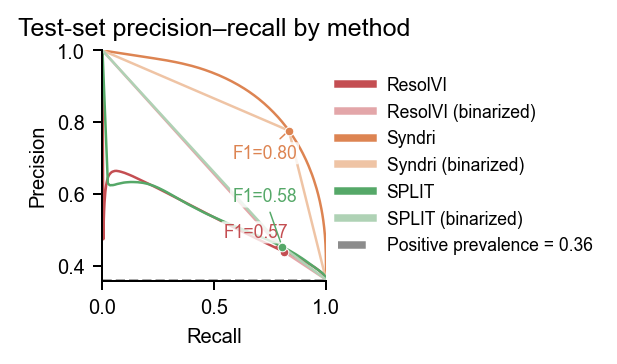

In [29]:
from matplotlib.legend_handler import HandlerLine2D
pr_fig, pr_ax = plt.subplots(figsize=(2.3,1.8), dpi=180)
# Annotate best F1 only for the unbinarized methods.
f1_annotation_offsets = {
    'ResolVI': (0.54, 0.48),
    'Syndri': (0.58, 0.70),
    'SPLIT': (0.58, 0.58),
}
for method in pr_method_order:
    method_pr = pr_data.loc[pr_data['method'].eq(method)].sort_values('x')
    if method_pr.empty:
        continue
    auprc_value = float(method_pr['auprc'].iloc[0])
    pr_ax.plot(method_pr['x'], method_pr['y'], color=curve_colors[method], lw=1,
               label=method)

    # Place the exact cached best-F1 value at the highest-F1 point retained in
    # the thinned curve. The plotted point is approximate; the score is exact.
    best_f1 = float(method_pr['best_f1'].iloc[0])
    if np.isfinite(best_f1) and method in {'ResolVI', 'Syndri', 'SPLIT'}:
        plotted_f1 = 2 * method_pr['x'] * method_pr['y'] / (method_pr['x'] + method_pr['y'])
        plotted_f1 = plotted_f1.replace([np.inf, -np.inf], np.nan).fillna(0)
        best_point = method_pr.iloc[int(np.argmax(plotted_f1.to_numpy()))]
        pr_ax.scatter([best_point['x']], [best_point['y']], s=12,
                      color=curve_colors[method], edgecolor='white', linewidth=0.4,
                      zorder=4)
        pr_ax.annotate(
            f'F1={best_f1:.2f}',
            xy=(best_point['x'], best_point['y']),
            xytext=f1_annotation_offsets.get(method, (0.5, 0.5)),
            textcoords='data', fontsize=7, color=curve_colors[method],
            bbox={'boxstyle': 'round,pad=0.12', 'facecolor': 'white',
                  'edgecolor': 'none', 'alpha': 0.8},
            arrowprops={'arrowstyle': '-', 'color': curve_colors[method], 'lw': 0.6},
            annotation_clip=True,
        )
if not pr_data.empty:
    prevalence = float(pr_data['positive_prevalence'].iloc[0])
    pr_ax.axhline(prevalence, color='0.55', ls='--', lw=1,
                  label=f'Positive prevalence = {prevalence:.2f}')
if not {'SPLIT', 'SPLIT (binarized)'}.issubset(set(pr_data['method'])):
    pr_ax.text(0.98, 0.04, 'SPLIT pending', ha='right', va='bottom',
               transform=pr_ax.transAxes, color='0.45', fontsize=8)
pr_ax.set(xlim=(0, 1), ylim=(0.36, 1), xlabel='Recall', ylabel='Precision')
pr_ax.set_title('Test-set precision–recall by method', fontsize=10)
pr_ax.set_xlabel('Recall', fontsize=8)
pr_ax.set_ylabel('Precision', fontsize=8)
pr_ax.tick_params(axis='both', labelsize=8)
leg = pr_ax.legend(frameon=False, loc='center left', fontsize=7,
                   bbox_to_anchor=(1.02, 0.5), borderaxespad=0)
for line in leg.get_lines():
    line.set_linewidth(3.0)
# pr_ax.grid(True, alpha=0.2)
pr_fig.subplots_adjust(left=0.14, right=0.68, bottom=0.17, top=0.88)
pr_fig.savefig(FIGURE_DIR / 'Figure3_SyndriSIM_test_methods_pr.png', dpi=300, bbox_inches='tight')
pr_fig.savefig(FIGURE_DIR / 'Figure3_SyndriSIM_test_methods_pr.pdf', bbox_inches='tight')
pr_fig.savefig(FIGURE_DIR / 'Figure3_pr-curve.svg',bbox_inches='tight')
plt.show()


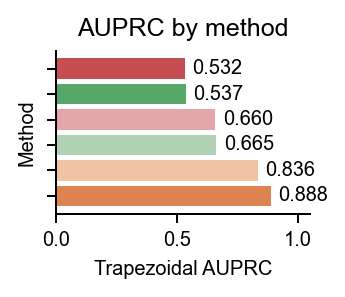

In [ ]:
# Show the trapezoidal AUPRC values separately from the PR-curve legend.
# Order from lowest AUPRC at the top to highest at the bottom.
auprc_plot = (
    pr_metric_summary.dropna(subset=['auprc'])
    .sort_values('auprc', ascending=True, kind='stable')
    .reset_index(drop=True)
)
auprc_fig, auprc_ax = plt.subplots(figsize=(2.0, 1.75), dpi=180)
auprc_bars = auprc_ax.barh(
    auprc_plot['method'], auprc_plot['auprc'],
    color=[curve_colors[method] for method in auprc_plot['method']],
)
auprc_ax.bar_label(auprc_bars, fmt='%.3f', padding=3, fontsize=8)
auprc_ax.set_xlim(0, 1.05)
auprc_ax.set_xlabel('Trapezoidal AUPRC', fontsize=8)
auprc_ax.set_ylabel('Method', fontsize=8)
auprc_ax.tick_params(axis='both', labelsize=8)
auprc_ax.invert_yaxis()
auprc_ax.set_title('AUPRC by method', fontsize=10)
# auprc_ax.grid(True, axis='x', alpha=0.2)
auprc_ax.spines[['right', 'top']].set_visible(False)
# axupr_ax.

# 2. Hide the left and top ticks/labels
auprc_ax.tick_params(left=True,labelleft=False, top=False, labeltop=False)
auprc_fig.tight_layout()
auprc_fig.savefig(
    FIGURE_DIR / 'Figure3_SyndriSIM_test_methods_auprc.png',
    dpi=300, bbox_inches='tight',
)
auprc_fig.savefig(
    FIGURE_DIR / 'Figure3_SyndriSIM_test_methods_auprc.pdf',
    bbox_inches='tight',
)
auprc_fig.savefig(
    FIGURE_DIR / 'Figure3_auprc-barplot.svg'
)
plt.show()


,method,best_f1,best_score_threshold,average_precision
0,Syndri,0.804466,0.762290,0.888386
1,Syndri (binarized),0.804466,0.762290,0.708173
2,SPLIT,0.580403,0.142894,0.533510
3,SPLIT (binarized),0.580403,0.142894,0.436269
4,ResolVI,0.570669,0.047124,0.532381
5,ResolVI (binarized),0.570668,0.047124,0.425106


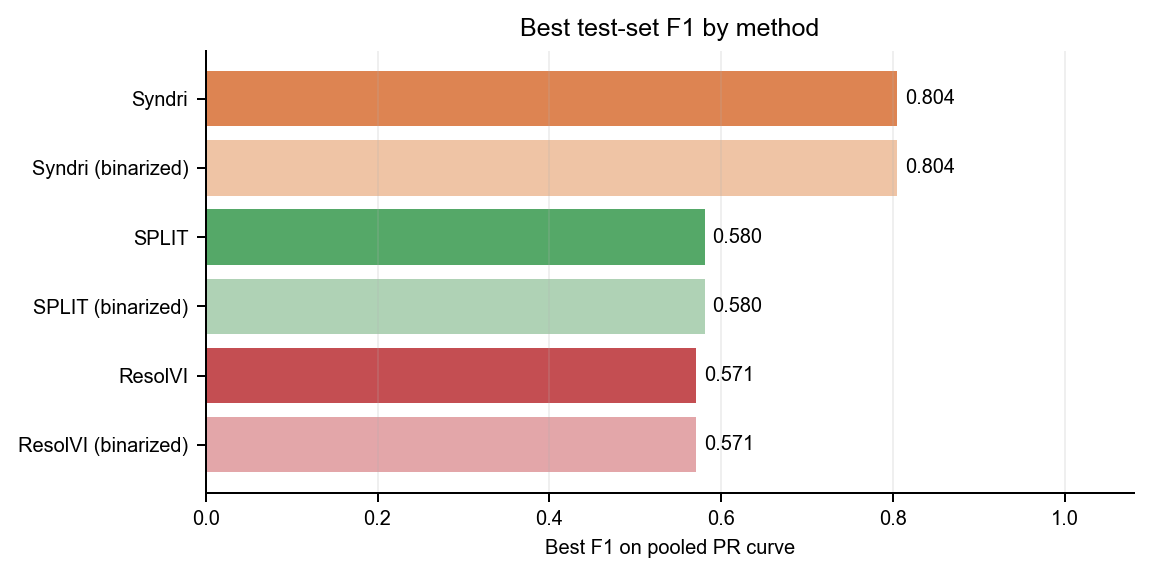

,cell_type,gene_aliases
0,T CD4+,"BTG1, FOXP3, IL7R"
1,T CD8+,"GZMH, CD8B, CD8A"
2,NK,"GNLY, XCL2, PRF1"
3,B cells,"MS4A1, CD37, CXCR5"
4,Plasmablast,"JCHAIN, FKBP11, CD38"
5,Monocyte,"TIMP1, S100A8, TNFRSF1B"
6,Macrophage,"C1QB, MMP19, GPX1"
7,DC,"COTL1, HLA-DPB1, HLA-DPA1"
8,Neutrophil,"IL1R2, ADGRG3, CXCR1"
9,Mast,"CPA3, HPGDS, PTGS1"


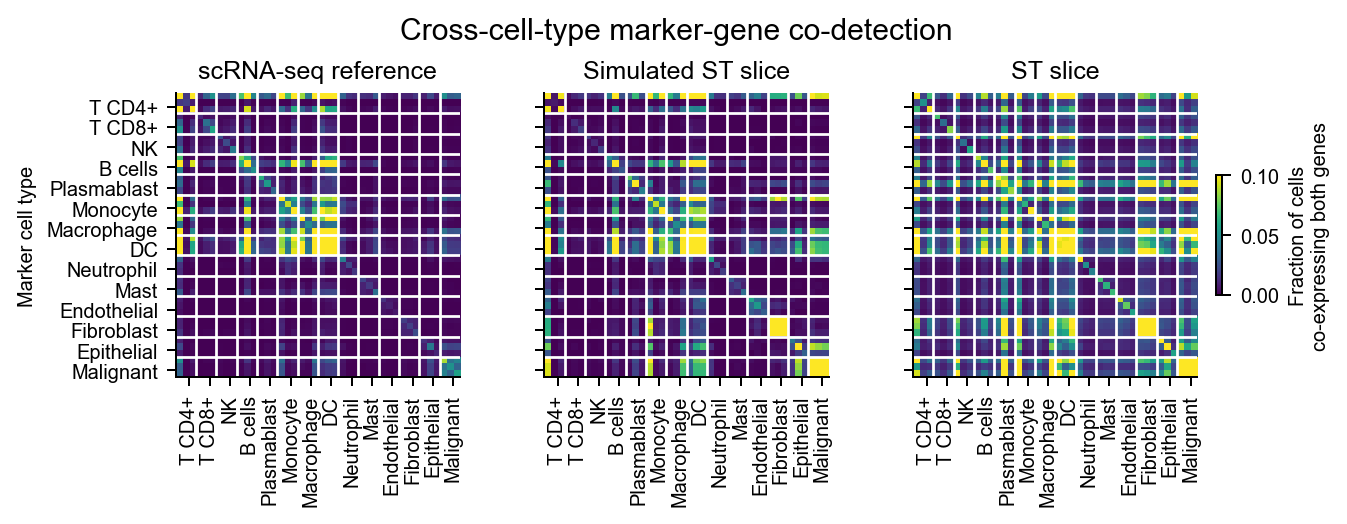

In [ ]:
# Best pooled F1 by method, plus marker-gene coexpression in the test slices.
# The PR cache stores the exact best F1 and threshold, even though plotted curves are thinned.
pr_data = method_curve_data.loc[method_curve_data['curve'].eq('PR')].copy()
best_f1_summary = (
    pr_data.groupby('method', sort=False)
    .agg(
        best_f1=('best_f1', 'first'),
        best_score_threshold=('best_f1_threshold', 'first'),
        average_precision=('metric_value', 'first'),
    )
    .reset_index()
)
display(best_f1_summary.sort_values('best_f1', ascending=False).reset_index(drop=True))

if not best_f1_summary.empty:
    f1_colors = curve_colors
    f1_plot = best_f1_summary.sort_values('best_f1')
    fig, ax = plt.subplots(figsize=(6.5, max(2.8, 0.55 * len(f1_plot))), dpi=180)
    bars = ax.barh(
        f1_plot['method'], f1_plot['best_f1'],
        color=[f1_colors.get(method, '#777777') for method in f1_plot['method']],
    )
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel('Best F1 on pooled PR curve', fontsize=8)
    ax.set_ylabel('', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_title('Best test-set F1 by method', fontsize=10)
    ax.grid(True, axis='x', alpha=0.2)
    fig.tight_layout()
    plt.show()

# Build one cross-cell-type coexpression matrix per dataset.
# Every entry uses all cells in that dataset (or the selected simulated slice).
import hashlib

COEXPRESSION_REFERENCE_PATH = TEST_ROOT / 'train_val_sc_reference_unique.h5ad'
COEXPRESSION_SIMULATED_PATH = TRAINING_PATH  # All train+val cells mapped to Lung5_Rep1.
COEXPRESSION_SPATIAL_PATH = Path(
    '/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final/'
    'st_integrated_slice-Lung5_Rep1.h5ad'
)
COEXPRESSION_MARKER_FILE = Path(
    '/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/markers/'
    'pydeseq2/candidate_cell_type_markers_deseq2.csv'
)
COEXPRESSION_CELL_TYPE_COL = 'cell_type_harmonized'
COEXPRESSION_SLICE_COL = 'spatial_slice'
COEXPRESSION_SLICE = 'Lung5_Rep1'
N_COEXPRESSION_GENES_PER_CELL_TYPE = 3
COEXPRESSION_CACHE_CSV = FIGURE_DIR / 'Figure3_SyndriSIM_Lung5_Rep1_coexpression_matrices.csv'

coexpression_paths = {
    'scRNA-seq reference': COEXPRESSION_REFERENCE_PATH,
    'Simulated ST slice': COEXPRESSION_SIMULATED_PATH,
    'ST slice': COEXPRESSION_SPATIAL_PATH,
}
coexpression_adatas = {
    name: ad.read_h5ad(path, backed='r') for name, path in coexpression_paths.items()
}
try:
    for name, adata in coexpression_adatas.items():
        if COEXPRESSION_CELL_TYPE_COL not in adata.obs:
            raise KeyError(f'{name} is missing obs[{COEXPRESSION_CELL_TYPE_COL!r}]')
    if COEXPRESSION_SLICE_COL not in coexpression_adatas['Simulated ST slice'].obs:
        raise KeyError(f'Simulated data is missing obs[{COEXPRESSION_SLICE_COL!r}]')

    available_gene_sets = [set(adata.var_names.astype(str)) for adata in coexpression_adatas.values()]
    common_gene_ids = set.intersection(*available_gene_sets)
    common_cell_types = []
    for dataset_name, adata in coexpression_adatas.items():
        type_values = adata.obs[COEXPRESSION_CELL_TYPE_COL].astype(str).to_numpy()
        if dataset_name == 'Simulated ST slice':
            slice_values = adata.obs[COEXPRESSION_SLICE_COL].astype(str).to_numpy()
            type_values = type_values[slice_values == COEXPRESSION_SLICE]
        common_cell_types.append(set(type_values))
    common_cell_types = set.intersection(*common_cell_types)
    # Keep the same family and within-family order as Figure2_UMAPs_CosMx.ipynb.
    coexpression_cell_type_families = [
        ('Lymphoid', ['T CD4+', 'T CD8+', 'Treg', 'NK', 'B cells', 'Plasmablast']),
        ('Myeloid / innate', ['Monocyte', 'Macrophage', 'DC', 'Neutrophil', 'Mast']),
        ('Stromal / vascular', ['Endothelial', 'Fibroblast']),
        ('Epithelial', ['Epithelial']),
        ('Malignant', ['Malignant']),
    ]
    coexpression_cell_type_order = [
        cell_type
        for _, family_cell_types in coexpression_cell_type_families
        for cell_type in family_cell_types
    ]
    unexpected_cell_types = common_cell_types - set(coexpression_cell_type_order)
    if unexpected_cell_types:
        raise ValueError(
            'Cell types are missing from the Figure 2 family order: '
            f'{sorted(unexpected_cell_types)}'
        )
    common_cell_types = [
        cell_type for cell_type in coexpression_cell_type_order
        if cell_type in common_cell_types
    ]
    marker_candidates = pd.read_csv(COEXPRESSION_MARKER_FILE).dropna(
        subset=['cell_type', 'gene', 'padj']
    ).sort_values(
        ['cell_type', 'padj', 'log2FoldChange'],
        ascending=[True, True, False], kind='stable',
    )
    alias_series = coexpression_adatas['scRNA-seq reference'].var['gene_symbol']
    gene_aliases = alias_series.astype(str).to_dict()

    coexpression_genes_by_cell_type = {}
    for cell_type in common_cell_types:
        ranked = marker_candidates.loc[
            marker_candidates['cell_type'].astype(str).eq(cell_type), 'gene'
        ].astype(str).tolist()
        selected = []
        for gene_id in ranked:
            alias = gene_aliases.get(gene_id, '')
            if gene_id in common_gene_ids and alias.strip() and alias.lower() != 'nan':
                if gene_id not in selected:
                    selected.append(gene_id)
            if len(selected) == N_COEXPRESSION_GENES_PER_CELL_TYPE:
                break
        if len(selected) < N_COEXPRESSION_GENES_PER_CELL_TYPE:
            raise ValueError(
                f'{cell_type} has only {len(selected)} shared genes with aliases; '
                f'{N_COEXPRESSION_GENES_PER_CELL_TYPE} are required.'
            )
        coexpression_genes_by_cell_type[cell_type] = selected

    # Gene symbols from the scRNA-seq reference provide readable axis labels.
    coexpression_axis = []
    for cell_type, gene_ids in coexpression_genes_by_cell_type.items():
        for gene_id in gene_ids:
            coexpression_axis.append({
                'cell_type': cell_type,
                'gene_id': gene_id,
                'alias': gene_aliases[gene_id],
            })
    axis_aliases = [entry['alias'] for entry in coexpression_axis]
    selection_text = repr((
        'cross-cell-type co-detection across all selected cells',
        [(entry['cell_type'], entry['gene_id'], entry['alias'])
         for entry in coexpression_axis],
    ))
    coexpression_signature = hashlib.sha256(selection_text.encode()).hexdigest()

    cache_columns = {
        'dataset', 'row_index', 'column_index', 'cell_type',
        'gene_1_alias', 'gene_2_alias', 'double_positive_fraction',
        'n_cells', 'selection_signature',
    }
    use_coexpression_cache = (
        'coexpression_matrix' not in RESULTS_TO_RECOMPUTE
        and COEXPRESSION_CACHE_CSV.is_file()
    )
    if use_coexpression_cache:
        coexpression_cache = pd.read_csv(COEXPRESSION_CACHE_CSV)
        use_coexpression_cache = (
            cache_columns.issubset(coexpression_cache.columns)
            and not coexpression_cache.empty
            and coexpression_cache['selection_signature'].eq(coexpression_signature).all()
        )
    if not use_coexpression_cache:
        coexpression_rows = []
        for dataset_name, adata in coexpression_adatas.items():
            # Include every cell in each dataset; only restrict the simulated
            # reference to the Lung5_Rep1 slice. Cell-type labels select markers,
            # but do not filter the cells used in any matrix entry.
            if dataset_name == 'Simulated ST slice':
                slice_values = adata.obs[COEXPRESSION_SLICE_COL].astype(str).to_numpy()
                selected_rows = np.flatnonzero(slice_values == COEXPRESSION_SLICE)
            else:
                selected_rows = np.arange(adata.n_obs)
            gene_ids = [entry['gene_id'] for entry in coexpression_axis]
            gene_indices = adata.var_names.get_indexer(gene_ids)
            if (gene_indices < 0).any():
                raise ValueError(f'{dataset_name} is missing selected genes.')
            # Read only selected cells and marker genes from the backed count matrix.
            selected_counts = adata.X[selected_rows, :][:, gene_indices]
            detected = dense_matrix(selected_counts) > 0
            matrix_size = len(coexpression_axis)
            # Each matrix entry is the fraction of all selected cells that
            # detect both genes, including pairs whose markers come from
            # different cell types.
            detected_float = detected.astype(np.float32)
            coexpressed_fraction = (detected_float.T @ detected_float) / len(selected_rows)
            for matrix_i in range(matrix_size):
                for matrix_j in range(matrix_size):
                    coexpression_rows.append({
                        'dataset': dataset_name,
                        'row_index': matrix_i,
                        'column_index': matrix_j,
                        'cell_type': 'all_selected_cells',
                        'gene_1_alias': axis_aliases[matrix_i],
                        'gene_2_alias': axis_aliases[matrix_j],
                        'double_positive_fraction': float(
                            coexpressed_fraction[matrix_i, matrix_j]
                        ),
                        'n_cells': int(len(selected_rows)),
                        'selection_signature': coexpression_signature,
                    })
            print(f'{dataset_name}: {len(selected_rows):,} selected cells')
        coexpression_cache = pd.DataFrame(coexpression_rows, columns=sorted(cache_columns))
        coexpression_cache.to_csv(COEXPRESSION_CACHE_CSV, index=False)
        print(f'Saved coexpression matrices to {COEXPRESSION_CACHE_CSV}')

    display(pd.DataFrame([
        {'cell_type': cell_type,
         'gene_aliases': ', '.join(gene_aliases[gene] for gene in genes)}
        for cell_type, genes in coexpression_genes_by_cell_type.items()
    ]))

    matrix_names = list(coexpression_paths)
    coexpression_matrices = {}
    matrix_size = len(coexpression_axis)
    for dataset_name in matrix_names:
        matrix = np.full((matrix_size, matrix_size), np.nan, dtype=np.float32)
        rows = coexpression_cache.loc[coexpression_cache['dataset'].eq(dataset_name)]
        for row in rows.itertuples(index=False):
            matrix[int(row.row_index), int(row.column_index)] = row.double_positive_fraction
        coexpression_matrices[dataset_name] = matrix

    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#F0F0F0')
    cell_type_labels = list(coexpression_genes_by_cell_type)
    group_centers = np.cumsum([
        len(genes) for genes in coexpression_genes_by_cell_type.values()
    ]) - np.asarray([
        len(genes) / 2 for genes in coexpression_genes_by_cell_type.values()
    ])
    family_axis_centers = []
    family_axis_labels = []
    family_column_start = 0
    for family_name, family_types in coexpression_cell_type_families:
        present_types = [
            cell_type for cell_type in family_types
            if cell_type in coexpression_genes_by_cell_type
        ]
        family_n_columns = sum(
            len(coexpression_genes_by_cell_type[cell_type])
            for cell_type in present_types
        )
        if family_n_columns:
            family_axis_centers.append(
                family_column_start + (family_n_columns - 1) / 2
            )
            family_axis_labels.append(family_name)
            family_column_start += family_n_columns
    fig, axes = plt.subplots(1, 3, figsize=(7.35, 2.8), dpi=180, constrained_layout=True)
    for ax, dataset_name in zip(axes, matrix_names):
        matrix = np.ma.masked_invalid(coexpression_matrices[dataset_name])
        image = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=.1, interpolation='nearest')
        ax.set_title(dataset_name, fontsize=10)
        ax.set_xticks(group_centers, cell_type_labels, rotation=90, ha='center', fontsize=8)
        ax.set_yticks(group_centers, cell_type_labels, fontsize=8)
        ax.set_xlabel('')
        # family_axis = ax.secondary_xaxis('top')
        # family_axis.spines['top'].set_position(('outward', 4))
        # family_axis.set_xticks(family_axis_centers, family_axis_labels)
        # family_axis.tick_params(
        #     axis='x', length=0, pad=1, labelsize=8, labelrotation=90,
        # )
        if ax is axes[0]:
            ax.set_ylabel('Marker cell type', fontsize=8)
        else:
            ax.set_yticklabels([])
        boundary = 0
        for cell_type, genes in coexpression_genes_by_cell_type.items():
            boundary += len(genes)
            if boundary < matrix_size:
                ax.axhline(boundary - 0.5, color='white', linewidth=1.1)
                ax.axvline(boundary - 0.5, color='white', linewidth=1.1)
    colorbar = fig.colorbar(
        image, ax=axes, shrink=0.42, pad=0.015,
        label='Fraction of cells\nco-expressing both genes',orientation='vertical',
    )
    colorbar.set_label('Fraction of cells\nco-expressing both genes', fontsize=8)
    colorbar.ax.tick_params(labelsize=8)
    fig.suptitle(
        'Cross-cell-type marker-gene co-detection',
        fontsize=12,
    )
    fig.savefig(
        FIGURE_DIR / 'Figure3_SyndriSIM_Lung5_Rep1_coexpression_matrices.png',
        dpi=300, bbox_inches='tight',
    )
    fig.savefig(
        FIGURE_DIR / 'Figure3_SyndriSIM_Lung5_Rep1_coexpression_matrices.pdf',
        bbox_inches='tight',
    )
    fig.savefig(
            FIGURE_DIR / 'Figure3_codetection.svg',
            bbox_inches='tight',
        )
    plt.show()
finally:
    for adata in coexpression_adatas.values():
        adata.file.close()


## Cell-type adjacency enrichment: Lung5_Rep1
Build directed 6-nearest-neighbor graphs and calculate \(\log_2(\mathrm{observed}/\mathrm{expected})\) enrichment for each ordered query-cell-type/neighbor-cell-type pair. The main plot uses the query-to-neighbor direction: simulated values are above the diagonal and real ST values are below it. Diagonal entries show the mean of real and simulated enrichment. The following cell shows the reverse direction using the same triangular layout. Both plots share a centered color scale and the co-detection matrix cell-type order. Set `cell_type_adjacency` in `RESULTS_TO_RECOMPUTE` to rebuild cached values.


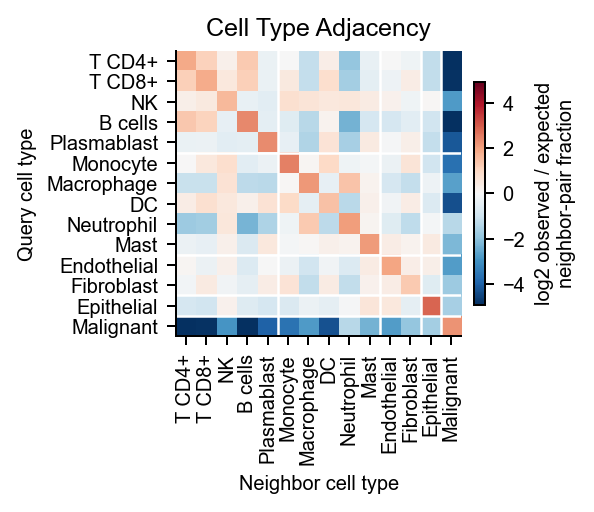

In [49]:
real_adjacency = adjacency_matrices['Real ST slice']
simulated_adjacency = adjacency_matrices['Simulated ST slice']
n_types = len(adjacency_cell_type_order)

# Split paired directed enrichment values by triangle. Rows are query types;
# columns are neighbor types. The diagonal shows the mean of both datasets.
family_boundaries = []
family_start = 0
for family_name, family_types in coexpression_cell_type_families:
    family_n = sum(cell_type in adjacency_cell_type_order for cell_type in family_types)
    if family_n:
        family_start += family_n
        if family_start < n_types:
            family_boundaries.append(family_start - .5)
all_adjacency_values = np.concatenate([real_adjacency.ravel(), simulated_adjacency.ravel()])
color_limit = max(1.0, float(np.nanpercentile(np.abs(all_adjacency_values), 98)))
adjacency_norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)


def plot_directional_adjacency(real_matrix, simulated_matrix, title, output_stem):
    upper = np.triu(np.ones((n_types, n_types), dtype=bool), k=1)
    lower = np.tril(np.ones((n_types, n_types), dtype=bool), k=-1)
    displayed = np.full((n_types, n_types), np.nan, dtype=float)
    displayed[upper] = simulated_matrix[upper]
    displayed[lower] = real_matrix[lower]
    diagonal = np.diag_indices(n_types)
    displayed[diagonal] = (real_matrix[diagonal] + simulated_matrix[diagonal]) / 2
    fig, ax = plt.subplots(figsize=(3.4, 3), dpi=180)
    fig.subplots_adjust(left=.24, right=.74, bottom=.35, top=.87)
    image = ax.imshow(np.ma.masked_invalid(displayed), cmap='RdBu_r',
                      norm=adjacency_norm, interpolation='nearest', aspect='equal')
    ax.set_title(title, fontsize=10)
    ax.set_xticks(np.arange(n_types), adjacency_cell_type_order,
                  rotation=90, ha='center', fontsize=8)
    ax.set_yticks(np.arange(n_types), adjacency_cell_type_order, fontsize=8)
    ax.set_xlabel('Neighbor cell type', fontsize=8)
    ax.set_ylabel('Query cell type', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    for boundary in family_boundaries:
        ax.axhline(boundary, color='white', linewidth=1.0)
        ax.axvline(boundary, color='white', linewidth=1.0)
    colorbar = fig.colorbar(image, ax=ax, fraction=.046, pad=.04,shrink=0.75)
    colorbar.set_label('log2 observed / expected\nneighbor-pair fraction', fontsize=8)
    colorbar.ax.tick_params(labelsize=8)
    # fig.text(.5, .045, 'Upper triangle: Simulated ST   |   Lower triangle: Real ST',
    #          ha='center', fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{output_stem}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{output_stem}.pdf', bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'Figure3_adjacency.svg', bbox_inches='tight')
    plt.show()


plot_directional_adjacency(
    real_adjacency, simulated_adjacency,
    'Cell Type Adjacency',
    'Figure3_SyndriSIM_Lung5_Rep1_cell_type_adjacency',
)


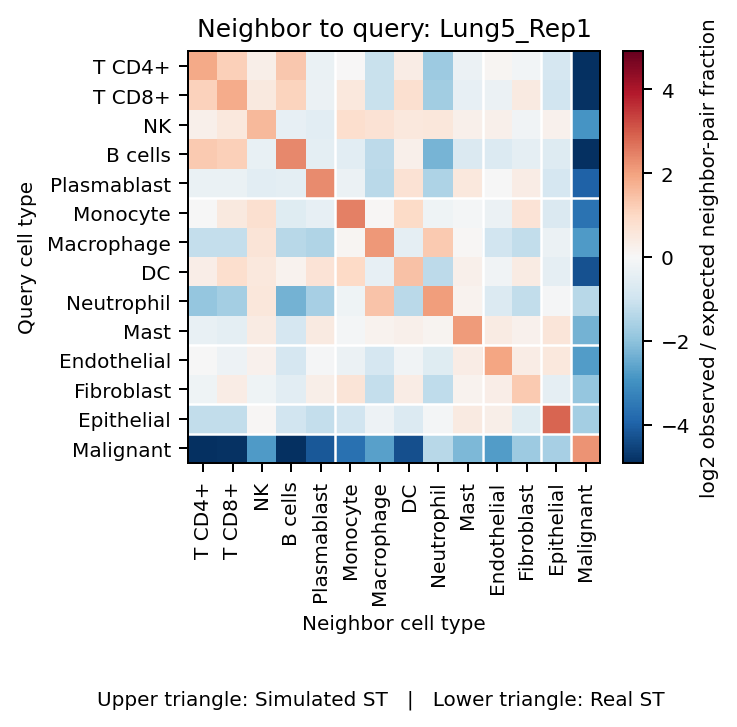

In [ ]:
# Reverse the directed statistic: neighbor type around query type.
# The same source color scale and triangular real/simulated assignment are used.
plot_directional_adjacency(
    real_adjacency.T,
    simulated_adjacency.T,
    'Neighbor to query: Lung5_Rep1',
    'Figure3_SyndriSIM_Lung5_Rep1_cell_type_adjacency_reverse_direction',
)
